# Итоговый проект: что связано с массой тела пингвинов?

**Автор:** Мезенцев Иван
**Учебная группа:** BHEBDPS-SAI-24-PAD-5
**Дата:** ноябрь 2026 года


**Цель:** исследовать различия между пингвинами трёх видов и построить линейную модель массы тела по морфологическим измерениям, виду и полу.

**Вопросы исследования**

1. Чем отличаются масса и размеры птиц разных видов?
2. Различается ли средняя масса самцов и самок внутри вида Adelie?
3. Какие измерения линейно связаны с массой и насколько точно позволяют её прогнозировать?

Единица наблюдения - отдельный пингвин. Это наблюдательные данные: найденные связи не доказывают причинного влияния. Год описывает момент сбора, но строки не образуют временной ряд одной величины.

## Источник и воспроизводимость

Использован открытый **Palmer Penguins**, подготовленный авторами пакета `palmerpenguins` на основе измерений Kristen Gorman и Palmer Station LTER. Набор включает 344 птицы, три вида и три острова за 2007–2009 годы; лицензия CC0.

- [Официальная страница проекта](https://allisonhorst.github.io/palmerpenguins/).
- [Исходный для этой работы CSV, версия v0.1.0](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/v0.1.0/inst/extdata/penguins.csv).
- [Описание переменных авторами](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html).
- Horst A. M., Hill A. P., Gorman K. B. (2020). *palmerpenguins: Palmer Archipelago (Antarctica) penguin data*. [DOI: 10.5281/zenodo.3960218](https://doi.org/10.5281/zenodo.3960218).

Файл `data/penguins.csv` приложен без изменений. Это опубликованная авторами сокращённая таблица из восьми признаков, а не полный полевой журнал `penguins_raw`. Самостоятельный сбор данных не проводился.

**Структура:** 1 - данные; 2 - пропуски и выбросы; 3 - фильтрация и новые признаки; 4 - частоты и сводные таблицы; 5 - статистика; 6 - гипотеза; 7 - визуализация; 8 - корреляции; 9 - регрессия; 10 - выводы.

In [1]:
from pathlib import Path
import hashlib
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

SPECIES_ORDER = ["Adelie", "Chinstrap", "Gentoo"]
PALETTE = dict(zip(SPECIES_ORDER, sns.color_palette("colorblind", 3)))
NUMERIC = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORICAL = ["species", "island", "sex"]
LABELS = {
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Высота клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса тела, г",
    "bill_ratio": "Отношение длины к высоте клюва",
}
print("Python:", platform.python_version())
display(pd.Series({p: version(p) for p in [
    "pandas", "numpy", "matplotlib", "seaborn", "scipy", "scikit-learn"
]}, name="Версия").to_frame())

Python: 3.12.4


,Версия
pandas,3.1.1
numpy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2
scipy,1.18.1
scikit-learn,1.9.1


## 1. Загрузка и описание данных

Читаем локальный CSV в `df_raw`, сохраняя исходную таблицу для проверки качества. Строки `NA` распознаются как пропуски. Сначала проверим размер, первые строки и реальные типы pandas. Целевая переменная - `body_mass_g` (масса в граммах).

In [20]:
DATA_PATH = Path("data/penguins.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError("Запустите ноутбук из папки проекта с файлом data/penguins.csv")

expected_sha256 = "f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93"
actual_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha256 == expected_sha256, "CSV отличается от приложенной версии источника"

df_raw = pd.read_csv(DATA_PATH, na_values=["NA"])
assert df_raw.shape == (344, 8)
print(f"Исходные данные: {df_raw.shape[0]} наблюдения, {df_raw.shape[1]} признаков.")
print("SHA-256:", actual_sha256)
display(df_raw.head())
df_raw.info()

Исходные данные: 344 наблюдения, 8 признаков.
SHA-256: f204db2c753b0937caac3cb35258562c14f073e4bbc76be24b4c51ce22767a93


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.10,18.70,181.00,"3,750.00",male,2007
1,Adelie,Torgersen,39.50,17.40,186.00,"3,800.00",female,2007
2,Adelie,Torgersen,40.30,18.00,195.00,"3,250.00",female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.70,19.30,193.00,"3,450.00",female,2007


<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


### Словарь всех исходных признаков

| Признак | Содержательное описание | Шкала и единица | Тип при чтении CSV |
|---|---|---|---|
| species | Вид: Adelie, Chinstrap, Gentoo | Номинальный | строковый |
| island | Остров: Biscoe, Dream, Torgersen | Номинальный | строковый |
| bill_length_mm | Длина клюва | Количественный, мм | float64 |
| bill_depth_mm | Высота (глубина) клюва | Количественный, мм | float64 |
| flipper_length_mm | Длина ласта | Количественный, мм | float64 из-за NA |
| body_mass_g | Масса тела, целевая переменная | Количественный, г | float64 из-за NA |
| sex | Пол: female / male | Номинальный | строковый |
| year | Год наблюдения: 2007, 2008, 2009 | Дискретный контекст сбора | int64 |

Конкретный строковый dtype зависит от версии pandas и показан ниже. `year` не включаем в корреляции размеров и регрессию: цель - объяснить массу по характеристикам птицы, а не по календарной метке. В модели также не используем остров, тесно связанный с видовым составом.

In [21]:
descriptions = {
    "species": "Вид пингвина",
    "island": "Остров наблюдения",
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Высота клюва, мм",
    "flipper_length_mm": "Длина ласта, мм",
    "body_mass_g": "Масса тела, г - целевая переменная",
    "sex": "Пол пингвина",
    "year": "Год сбора наблюдения",
}
dictionary = pd.DataFrame({
    "Описание": pd.Series(descriptions),
    "Фактический dtype": df_raw.dtypes.astype(str),
    "Уникальных без NA": df_raw.nunique(),
})
display(dictionary)

,Описание,Фактический dtype,Уникальных без NA
species,Вид пингвина,str,3
island,Остров наблюдения,str,3
bill_length_mm,"Длина клюва, мм",float64,164
bill_depth_mm,"Высота клюва, мм",float64,80
flipper_length_mm,"Длина ласта, мм",float64,55
body_mass_g,"Масса тела, г — целевая переменная",float64,94
sex,Пол пингвина,str,2
year,Год сбора наблюдения,int64,3


## 2. Пропуски, дубликаты и выбросы

### 2.1. Пропуски

Проверяем **все** столбцы. Для сопоставимости последующих этапов используем полные наблюдения по исходным восьми признакам. Массу не заполняем, чтобы не подменять целевую переменную вымышленными значениями; пол не восстанавливаем по размерам, иначе можно искусственно усилить различия групп.

Удаление небольшой доли строк проще интерпретировать, однако оно не гарантирует отсутствия смещения. Сопоставим видовой состав до и после обработки. Все последующие расчёты выполняются на отдельном `df_clean`.

In [22]:
missing_table = pd.DataFrame({
    "Пропусков": df_raw.isna().sum(),
    "Доля, %": df_raw.isna().mean() * 100,
})
display(missing_table)
print("Полностью совпадающих строк:", df_raw.duplicated().sum())

# Удаляем только полностью совпадающие записи, затем неполные строки.
df_clean = df_raw.drop_duplicates().dropna(subset=df_raw.columns).copy()
for column in CATEGORICAL:
    df_clean[column] = df_clean[column].astype("category")

removed_n = len(df_raw) - len(df_clean)
composition = pd.concat({
    "До очистки, %": df_raw["species"].value_counts(normalize=True) * 100,
    "После очистки, %": df_clean["species"].value_counts(normalize=True) * 100,
}, axis=1).reindex(SPECIES_ORDER)
display(composition)
assert df_clean.isna().sum().sum() == 0
assert len(df_clean) >= 100
display(Markdown(
    f"**Результат:** исключено {removed_n} строк ({removed_n / len(df_raw):.1%}); "
    f"осталось **{len(df_clean)}** наблюдения. "
    "Распределение видов изменилось слабо. Это не доказывает случайность пропусков: "
    "выводы относятся прежде всего к птицам с полными измерениями и известным полом."
))

,Пропусков,"Доля, %"
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Полностью совпадающих строк: 0


,"До очистки, %","После очистки, %"
species,,
Adelie,44.19,43.84
Chinstrap,19.77,20.42
Gentoo,36.05,35.74


**Результат:** исключено 11 строк (3.2%); осталось **333** наблюдения. Распределение видов изменилось слабо. Это не доказывает случайность пропусков: выводы относятся прежде всего к птицам с полными измерениями и известным полом.

### 2.2. Выбросы массы и длины ласта

Используем правило Тьюки: $IQR=Q_3-Q_1$, нижняя граница $Q_1-1.5IQR$, верхняя - $Q_3+1.5IQR$. Оно не требует нормальности и устойчивее среднего со стандартным отклонением.

Сначала оценим массу и длину ласта на всей очищенной выборке, затем **внутри каждого вида**: смешение видов может скрыть необычные для конкретного вида размеры. Выход за границы - диагностический сигнал, а не доказательство ошибки. Не удаляем биологически возможные крайние значения без подтверждения ошибки; не используем распределение тестовых данных для обрезки перед регрессией.

,n,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Выбросов
body_mass_g,333.00,"3,550.00","4,775.00","1,225.00","1,712.50","6,612.50",0.00
flipper_length_mm,333.00,190.00,213.00,23.00,155.50,247.50,0.00


n       Q1       Q3    IQR  Нижняя граница  \
Вид       Признак                                                             
Adelie    body_mass_g       146.00 3,362.50 4,000.00 637.50        2,406.25   
          flipper_length_mm 146.00   186.00   195.00   9.00          172.50   
Chinstrap body_mass_g        68.00 3,487.50 3,950.00 462.50        2,793.75   
          flipper_length_mm  68.00   191.00   201.00  10.00          176.00   
Gentoo    body_mass_g       119.00 4,700.00 5,500.00 800.00        3,500.00   
          flipper_length_mm 119.00   212.00   221.50   9.50          197.75   

                             Верхняя граница  Выбросов  
Вид       Признак                                       
Adelie    body_mass_g               4,956.25      0.00  
          flipper_length_mm           208.50      2.00  
Chinstrap body_mass_g               4,643.75      2.00  
          flipper_length_mm           216.00      0.00  
Gentoo    body_mass_g               6,700.00      0.00  
          flipper_length_mm           235.75      0.00

,species,sex,признак,значение
28,Adelie,female,flipper_length_mm,172.00
129,Adelie,male,flipper_length_mm,210.00
313,Chinstrap,male,body_mass_g,"4,800.00"
314,Chinstrap,female,body_mass_g,"2,700.00"


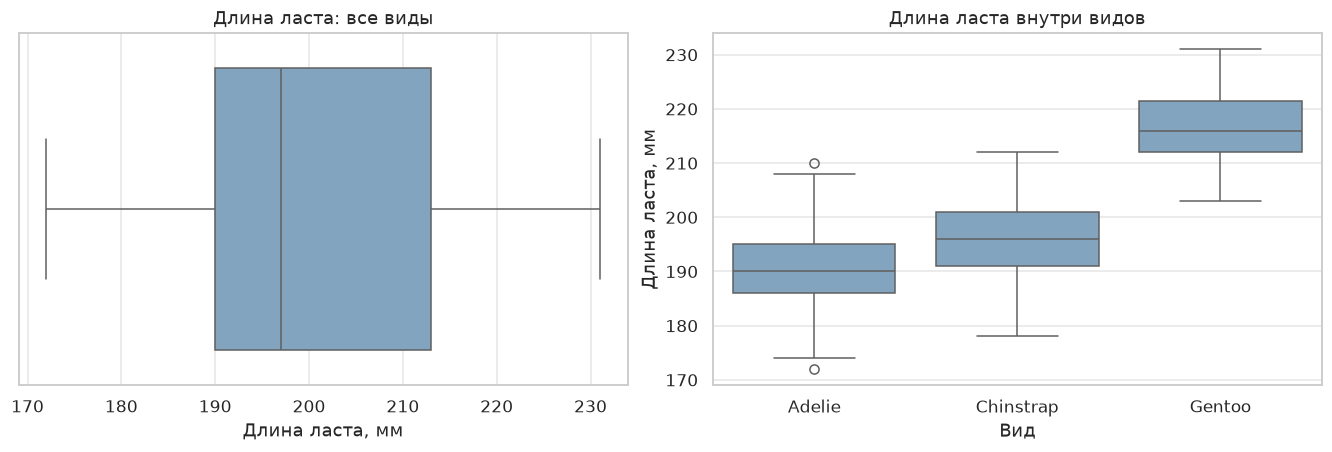

По общим границам: масса — **0** выбросов, длина ласта — **0**. Внутри видов отмечено 4 сочетаний «строка–признак». Их значения приведены в таблице; они возможны для живых птиц. **Решение:** сохранить наблюдения. df_clean содержит полные записи и сохраняет естественный разброс.

In [23]:
def iqr_summary(series):
    """Границы и число наблюдений вне интервала Тьюки."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return pd.Series({
        "n": len(series), "Q1": q1, "Q3": q3, "IQR": iqr,
        "Нижняя граница": lower, "Верхняя граница": upper,
        "Выбросов": int(mask.sum()),
    })

outlier_global = pd.DataFrame({
    column: iqr_summary(df_clean[column])
    for column in ["body_mass_g", "flipper_length_mm"]
}).T
display(outlier_global)

outlier_species = pd.DataFrame([
    {"Вид": species, "Признак": column, **iqr_summary(part[column]).to_dict()}
    for species, part in df_clean.groupby("species", observed=True)
    for column in ["body_mass_g", "flipper_length_mm"]
]).set_index(["Вид", "Признак"])
display(outlier_species)

flagged_parts = []
for species, part in df_clean.groupby("species", observed=True):
    for column in ["body_mass_g", "flipper_length_mm"]:
        info = iqr_summary(part[column])
        mask = ((part[column] < info["Нижняя граница"]) |
                (part[column] > info["Верхняя граница"]))
        flagged_parts.append(part.loc[mask, ["species", "sex"]].assign(
            признак=column, значение=part.loc[mask, column]
        ))
flagged = pd.concat(flagged_parts, axis=0)
display(flagged)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
sns.boxplot(data=df_clean, x="flipper_length_mm", ax=axes[0], color="#78a6c8")
axes[0].set(title="Длина ласта: все виды", xlabel="Длина ласта, мм")
sns.boxplot(data=df_clean, x="species", y="flipper_length_mm",
            order=SPECIES_ORDER, ax=axes[1], color="#78a6c8")
axes[1].set(title="Длина ласта внутри видов", xlabel="Вид", ylabel="Длина ласта, мм")
plt.show()

display(Markdown(
    f"По общим границам: масса - **{int(outlier_global.loc['body_mass_g', 'Выбросов'])}** "
    f"выбросов, длина ласта - **{int(outlier_global.loc['flipper_length_mm', 'Выбросов'])}**. "
    f"Внутри видов отмечено {len(flagged)} сочетаний «строка–признак». "
    "Их значения приведены в таблице; они возможны для живых птиц. "
    "**Решение:** сохранить наблюдения. df_clean содержит полные записи и сохраняет естественный разброс."
))

## 3. Фильтрация, сортировка и новые признаки

### 3.1. Одно условие

Выберем птиц массой не менее 5000 г и отсортируем по убыванию массы. Порог задан как содержательный ориентир «крупная птица», а не как статистическая граница выбросов. Для компактности показываем первые десять строк, число результатов считаем по всей выборке.

In [24]:
heavy = df_clean.loc[df_clean["body_mass_g"] >= 5000].sort_values(
    "body_mass_g", ascending=False
)
display(heavy.head(10))
display(heavy["species"].value_counts().rename("Количество").to_frame())
display(Markdown(
    f"Найдено **{len(heavy)}** птиц массой от 5000 г; "
    f"наибольшая масса - **{heavy['body_mass_g'].max():.0f} г**. "
    "Все птицы в этой выборке относятся к Gentoo: высокие значения массы связаны с видом."
))

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
169,Gentoo,Biscoe,49.20,15.20,221.00,"6,300.00",male,2007
185,Gentoo,Biscoe,59.60,17.00,230.00,"6,050.00",male,2007
269,Gentoo,Biscoe,48.80,16.20,222.00,"6,000.00",male,2009
229,Gentoo,Biscoe,51.10,16.30,220.00,"6,000.00",male,2008
231,Gentoo,Biscoe,45.20,16.40,223.00,"5,950.00",male,2008
263,Gentoo,Biscoe,49.80,15.90,229.00,"5,950.00",male,2009
167,Gentoo,Biscoe,49.30,15.70,217.00,"5,850.00",male,2007
267,Gentoo,Biscoe,55.10,16.00,230.00,"5,850.00",male,2009
165,Gentoo,Biscoe,48.40,14.60,213.00,"5,850.00",male,2007
227,Gentoo,Biscoe,48.60,16.00,230.00,"5,800.00",male,2008


,Количество
species,
Gentoo,67
Adelie,0
Chinstrap,0


Найдено **67** птиц массой от 5000 г; наибольшая масса - **6300 г**. Все птицы в этой выборке относятся к Gentoo: высокие значения массы связаны с видом.

### 3.2. Несколько условий

Выберем **самок Gentoo с ластом не короче 210 мм**, затем отсортируем по длине ласта и массе по убыванию. Такое сочетание условий позволяет исследовать крупные размеры внутри конкретной группы, не смешивая виды и пол.

In [25]:
gentoo_females = df_clean.loc[
    (df_clean["species"] == "Gentoo") &
    (df_clean["sex"] == "female") &
    (df_clean["flipper_length_mm"] >= 210)
].sort_values(["flipper_length_mm", "body_mass_g"], ascending=[False, False])
display(gentoo_females.head(10))
display(Markdown(
    f"Условиям соответствуют **{len(gentoo_females)}** самок Gentoo. "
    f"Их средняя масса - **{gentoo_females['body_mass_g'].mean():.0f} г**, "
    f"длина ласта - от **{gentoo_females['flipper_length_mm'].min():.0f}** "
    f"до **{gentoo_females['flipper_length_mm'].max():.0f} мм**. "
    "Сортировка ставит первыми птиц с наиболее длинными ластами."
))

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
249,Gentoo,Biscoe,46.90,14.60,222.00,"4,875.00",female,2009
186,Gentoo,Biscoe,49.10,14.80,220.00,"5,150.00",female,2008
220,Gentoo,Biscoe,43.50,14.20,220.00,"4,700.00",female,2008
252,Gentoo,Biscoe,48.50,15.00,219.00,"4,850.00",female,2009
216,Gentoo,Biscoe,45.80,14.20,219.00,"4,700.00",female,2008
242,Gentoo,Biscoe,47.50,15.00,218.00,"4,950.00",female,2009
238,Gentoo,Biscoe,43.40,14.40,218.00,"4,600.00",female,2009
225,Gentoo,Biscoe,46.50,14.80,217.00,"5,200.00",female,2008
197,Gentoo,Biscoe,43.60,13.90,217.00,"4,900.00",female,2008
206,Gentoo,Biscoe,46.50,14.40,217.00,"4,900.00",female,2008


Условиям соответствуют **46** самок Gentoo. Их средняя масса - **4727 г**, длина ласта - от **210** до **222 мм**. Сортировка ставит первыми птиц с наиболее длинными ластами.

### 3.3. Создание признаков

- **is_long_flipper** - бинарная категория: 1, если длина ласта не меньше 200 мм, иначе 0. Создаётся через `lambda`; порог - удобный ориентир около 20 см, а не биологическая классификация.
- **bill_ratio** - безразмерное отношение длины к высоте клюва, $L/D$. Создаётся собственной функцией; большее значение означает более вытянутый клюв.

Оба признака используют только характеристики птицы, без целевой массы. При моделировании оставим исходные измерения, чтобы не добавлять их производные и не усложнять интерпретацию.

In [26]:
df_clean["is_long_flipper"] = df_clean["flipper_length_mm"].apply(
    lambda length: 1 if length >= 200 else 0
).astype("int8")

def calculate_bill_ratio(row):
    """Относительная вытянутость клюва; защита от нулевого знаменателя."""
    if row["bill_depth_mm"] <= 0:
        return np.nan
    return row["bill_length_mm"] / row["bill_depth_mm"]

df_clean["bill_ratio"] = df_clean.apply(calculate_bill_ratio, axis=1)
assert df_clean["bill_ratio"].notna().all()
assert set(df_clean["is_long_flipper"].unique()) == {0, 1}
display(df_clean[["bill_length_mm", "bill_depth_mm", "bill_ratio",
                  "flipper_length_mm", "is_long_flipper"]].head())
display(Markdown(
    f"Доля птиц с ластом от 200 мм - **{df_clean['is_long_flipper'].mean():.1%}**. "
    f"Среднее отношение длины к высоте клюва - **{df_clean['bill_ratio'].mean():.2f}**. "
    "Бинарный признак имеет тип int8, отношение - float64."
))

,bill_length_mm,bill_depth_mm,bill_ratio,flipper_length_mm,is_long_flipper
0,39.10,18.70,2.09,181.00,0
1,39.50,17.40,2.27,186.00,0
2,40.30,18.00,2.24,195.00,0
4,36.70,19.30,1.90,193.00,0
5,39.30,20.60,1.91,190.00,0


Доля птиц с ластом от 200 мм - **44.4%**. Среднее отношение длины к высоте клюва - **2.61**. Бинарный признак имеет тип int8, отношение - float64.

## 4. Частотные и сводные таблицы

Частоты показывают состав выборки; простая сводная таблица - среднюю массу по видам; сложная - численность и несколько характеристик массы по сочетанию вида и пола. Все расчёты используют `df_clean`.

In [27]:
frequency = df_clean["species"].value_counts().sort_values(ascending=False).to_frame("Число")
frequency["Доля, %"] = frequency["Число"] / len(df_clean) * 100
display(frequency)

pivot_simple = df_clean.pivot_table(
    index="species", values="body_mass_g", aggfunc="mean", observed=True
).rename(columns={"body_mass_g": "Средняя масса, г"}).sort_values("Средняя масса, г", ascending=False)
display(pivot_simple)

pivot_complex = df_clean.pivot_table(
    index=["species", "sex"], values="body_mass_g",
    aggfunc=["count", "mean", "median", "std"], observed=True
)
pivot_complex.columns = ["n", "Среднее, г", "Медиана, г", "Станд. отклонение, г"]
display(pivot_complex)

species_means = df_clean.groupby("species", observed=True)["body_mass_g"].mean()
sex_means = df_clean.groupby(["species", "sex"], observed=True)["body_mass_g"].mean().unstack()
display(Markdown(
    f"Самый частый вид - **{frequency.index[0]}** "
    f"({frequency.iloc[0]['Доля, %']:.1f}% выборки). "
    f"Наибольшая средняя масса у **{species_means.idxmax()}** "
    f"({species_means.max():.0f} г), наименьшая - у **{species_means.idxmin()}** "
    f"({species_means.min():.0f} г). "
    "Самцы в среднем тяжелее самок в каждом виде; размеры групп различаются, "
    "поэтому общий средний вес зависит и от видового состава."
))
display((sex_means["male"] - sex_means["female"]).rename(
    "Разница средних male − female, г"
).to_frame())

,Число,"Доля, %"
species,,
Adelie,146,43.84
Gentoo,119,35.74
Chinstrap,68,20.42


,"Средняя масса, г"
species,
Gentoo,"5,092.44"
Chinstrap,"3,733.09"
Adelie,"3,706.16"


n  Среднее, г  Медиана, г  Станд. отклонение, г
species   sex                                                     
Adelie    female  73    3,368.84    3,400.00                269.38
          male    73    4,043.49    4,000.00                346.81
Chinstrap female  34    3,527.21    3,550.00                285.33
          male    34    3,938.97    3,950.00                362.14
Gentoo    female  58    4,679.74    4,700.00                281.58
          male    61    5,484.84    5,500.00                313.16

Самый частый вид - **Adelie** (43.8% выборки). Наибольшая средняя масса у **Gentoo** (5092 г), наименьшая - у **Adelie** (3706 г). Самцы в среднем тяжелее самок в каждом виде; размеры групп различаются, поэтому общий средний вес зависит и от видового состава.

,"Разница средних male − female, г"
species,
Adelie,674.66
Chinstrap,411.76
Gentoo,805.09


## 5. Описательная статистика

Для массы рассчитываем показатели положения и разброса. Используем **выборочную** дисперсию $s^2=\frac{\sum (x_i-\bar x)^2}{n-1}$ и стандартное отклонение $s=\sqrt{s^2}$ (`ddof=1`); размах равен $\max-\min$, межквартильный размах - $Q_3-Q_1$.

Для всех исходных категориальных признаков и нового бинарного признака находим моду и число уникальных значений. При равенстве частот показываем все моды.

In [28]:
mass = df_clean["body_mass_g"]
q1, q3 = mass.quantile([0.25, 0.75])
mass_stats = pd.Series({
    "Количество": mass.count(),
    "Среднее, г": mass.mean(),
    "Медиана, г": mass.median(),
    "Минимум, г": mass.min(),
    "Первый квартиль Q1, г": q1,
    "Третий квартиль Q3, г": q3,
    "Максимум, г": mass.max(),
    "Размах, г": mass.max() - mass.min(),
    "IQR, г": q3 - q1,
    "Выборочная дисперсия, г²": mass.var(ddof=1),
    "Выборочное стандартное отклонение, г": mass.std(ddof=1),
})
display(mass_stats.to_frame("Значение"))

category_stats = pd.DataFrame([
    {"Признак": column,
     "Мода (все значения)": ", ".join(map(str, df_clean[column].mode().tolist())),
     "Уникальных": df_clean[column].nunique()}
    for column in CATEGORICAL + ["is_long_flipper"]
]).set_index("Признак")
display(category_stats)
display(Markdown(
    f"Средняя масса - **{mass.mean():.0f} г**, медиана - **{mass.median():.0f} г**. "
    f"Центральные 50% наблюдений лежат от **{q1:.0f} до {q3:.0f} г**; "
    f"выборочное стандартное отклонение - **{mass.std(ddof=1):.0f} г**. "
    "Среднее выше медианы, что согласуется с более тяжёлой группой Gentoo; "
    "форму распределения дополнительно проверим графически. "
    "Моды категорий характеризуют наиболее частые группы выборки, "
    "а не типичный профиль всех пингвинов Антарктики."
))

,Значение
Количество,333.00
"Среднее, г","4,207.06"
"Медиана, г","4,050.00"
"Минимум, г","2,700.00"
"Первый квартиль Q1, г","3,550.00"
"Третий квартиль Q3, г","4,775.00"
"Максимум, г","6,300.00"
"Размах, г","3,600.00"
"IQR, г","1,225.00"
"Выборочная дисперсия, г²","648,372.49"


,Мода (все значения),Уникальных
Признак,,
species,Adelie,3
island,Biscoe,3
sex,male,2
is_long_flipper,0,2


Средняя масса - **4207 г**, медиана - **4050 г**. Центральные 50% наблюдений лежат от **3550 до 4775 г**; выборочное стандартное отклонение - **805 г**. Среднее выше медианы, что согласуется с более тяжёлой группой Gentoo; форму распределения дополнительно проверим графически. Моды категорий характеризуют наиболее частые группы выборки, а не типичный профиль всех пингвинов Антарктики.

## 6. Сравнение групп и одна статистическая гипотеза

Сравниваем массу **самцов и самок только вида Adelie**, чтобы различие видового состава не объясняло половой эффект.

$$H_0:\mu_{\mathrm{male}}=\mu_{\mathrm{female}},\qquad
H_1:\mu_{\mathrm{male}} ≠ \mu_{\mathrm{female}}.$$

Заранее выбираем двусторонний **t-критерий Уэлча**, $\alpha=0.05$: он проверяет равенство средних и не требует равенства дисперсий. Группы достаточно велики для приближения распределения среднего нормальным; экстремальные значения массы в Adelie по IQR не обнаружены. Доверительный интервал разницы средних рассчитываем с числом степеней свободы Уэлча–Саттертуэйта.

Независимость наблюдений - рабочее допущение: каждая строка относится к отдельной птице, но возможную зависимость через колонию или гнездовую пару в сокращённом CSV оценить нельзя. Одна проверка не требует поправки на множественные сравнения. Это сравнение ассоциаций, а не эксперимент о влиянии пола.

In [29]:
adelie = df_clean.loc[df_clean["species"] == "Adelie"]
group_stats = adelie.groupby("sex", observed=True)["body_mass_g"].agg(
    n="count", mean="mean", median="median", std="std",
    minimum="min", maximum="max"
)
display(group_stats)

male = adelie.loc[adelie["sex"] == "male", "body_mass_g"]
female = adelie.loc[adelie["sex"] == "female", "body_mass_g"]
ALPHA = 0.05
welch = stats.ttest_ind(male, female, equal_var=False, alternative="two-sided")

difference = male.mean() - female.mean()
a = male.var(ddof=1) / len(male)
b = female.var(ddof=1) / len(female)
standard_error = np.sqrt(a + b)
welch_df = (a + b) ** 2 / (a ** 2 / (len(male) - 1) + b ** 2 / (len(female) - 1))
critical_t = stats.t.ppf(1 - ALPHA / 2, df=welch_df)
ci_low, ci_high = difference + np.array([-1, 1]) * critical_t * standard_error
reject_null = welch.pvalue < ALPHA

print(f"t = {welch.statistic:.3f}; df = {welch_df:.2f}; p-value = {welch.pvalue:.3e}")
print(f"Разница средних (самцы − самки): {difference:.1f} г")
print(f"95% ДИ разницы средних: [{ci_low:.1f}; {ci_high:.1f}] г")
decision = "отвергаем H₀" if reject_null else "не отвергаем H₀"
display(Markdown(
    f"При α = {ALPHA} **{decision}**. В выборке Adelie самцы тяжелее самок "
    f"в среднем на **{difference:.0f} г** "
    f"({difference / female.mean():.1%} относительно средней массы самок). "
    f"95% доверительный интервал: **[{ci_low:.0f}; {ci_high:.0f}] г**. "
    "Результат говорит о различии средних при принятых допущениях; "
    "p-value не является вероятностью истинности H₀ и не оценивает размер различия."
))

,n,mean,median,std,minimum,maximum
sex,,,,,,
female,73,"3,368.84","3,400.00",269.38,"2,850.00","3,900.00"
male,73,"4,043.49","4,000.00",346.81,"3,325.00","4,775.00"


t = 13.126; df = 135.69; p-value = 6.402e-26
Разница средних (самцы − самки): 674.7 г
95% ДИ разницы средних: [573.0; 776.3] г


При α = 0.05 **отвергаем H₀**. В выборке Adelie самцы тяжелее самок в среднем на **675 г** (20.0% относительно средней массы самок). 95% доверительный интервал: **[573; 776] г**. Результат говорит о различии средних при принятых допущениях; p-value не является вероятностью истинности H₀ и не оценивает размер различия.

## 7. Визуализация: аналитический дашборд

Четыре связанных графика помогают последовательно увидеть распределение массы, состав выборки, различия внутри видов и связь массы с длиной ласта. На всех панелях используются одни и те же очищенные наблюдения. Гистограмма показывает частоты, а не вероятности; границы коробок - квартильные значения, линия внутри - медиана.

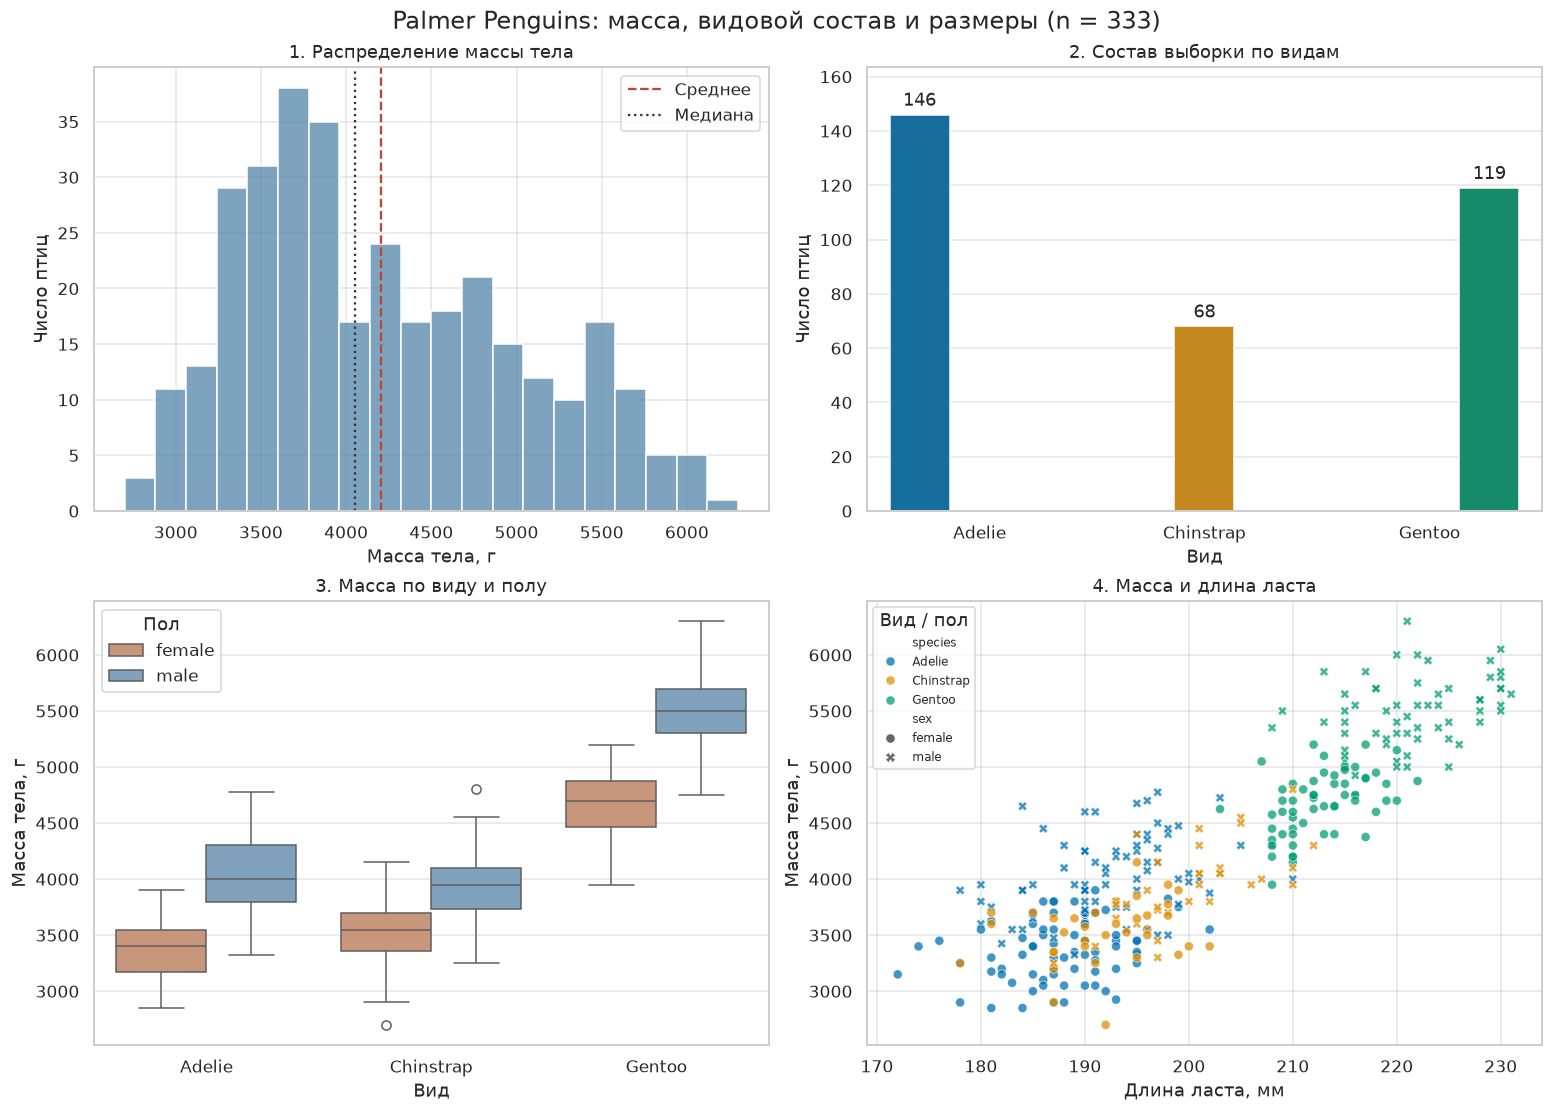

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout="constrained")
fig.suptitle("Palmer Penguins: масса, видовой состав и размеры (n = 333)", fontsize=16)

sns.histplot(data=df_clean, x="body_mass_g", bins=20, ax=axes[0, 0], color="#5284a8")
axes[0, 0].axvline(mass.mean(), color="#b84737", linestyle="--", label="Среднее")
axes[0, 0].axvline(mass.median(), color="#333333", linestyle=":", label="Медиана")
axes[0, 0].set(title="1. Распределение массы тела", xlabel="Масса тела, г", ylabel="Число птиц")
axes[0, 0].legend()

sns.countplot(data=df_clean, x="species", order=SPECIES_ORDER,
              hue="species", palette=PALETTE, legend=False, ax=axes[0, 1])
axes[0, 1].set(title="2. Состав выборки по видам", xlabel="Вид", ylabel="Число птиц")
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, padding=3)
axes[0, 1].margins(y=0.12)

sns.boxplot(data=df_clean, x="species", y="body_mass_g", hue="sex",
            order=SPECIES_ORDER, hue_order=["female", "male"],
            palette={"female": "#d5946e", "male": "#76a3c6"}, ax=axes[1, 0])
axes[1, 0].set(title="3. Масса по виду и полу", xlabel="Вид", ylabel="Масса тела, г")
axes[1, 0].legend(title="Пол")

sns.scatterplot(data=df_clean, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="sex", hue_order=SPECIES_ORDER,
                palette=PALETTE, alpha=0.75, ax=axes[1, 1])
axes[1, 1].set(title="4. Масса и длина ласта", xlabel="Длина ласта, мм", ylabel="Масса тела, г")
axes[1, 1].legend(title="Вид / пол", fontsize=8)
plt.show()

**Интерпретация дашборда.** Масса распределена неоднородно: в выборке смешаны группы с разным размером тела. Adelie встречается чаще других видов, а Chinstrap - реже. Коробки Gentoo расположены выше, чем у остальных видов; внутри каждого вида медиана самцов выше медианы самок. При увеличении длины ласта масса в целом растёт, но облака точек разделяются по виду. Поэтому общей корреляции недостаточно для объяснения индивидуальных различий - в модели нужно учитывать вид и пол.

## 8. Корреляционный анализ

<a id="correlation-analysis"></a>

Для массы и длины ласта рассчитываем коэффициент Пирсона $r\in[-1,1]$: знак показывает направление, модуль - выраженность **линейной** связи.

Матрица включает четыре исходных количественных измерения и новое отношение размеров клюва. Год исключён как контекст сбора, бинарный признак рассматривается как категория. Сильнейшую и слабейшую пары определяем по $|r|$ среди уникальных внедиагональных пар, а не по знаку коэффициента. Ранжирование - описательный анализ; дополнительные гипотезы о корреляциях не проверяем.

Корреляция Пирсона: масса и длина ласта, r = 0.873


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,bill_ratio
bill_length_mm,1.00,-0.23,0.65,0.59,0.78
bill_depth_mm,-0.23,1.00,-0.58,-0.47,-0.78
flipper_length_mm,0.65,-0.58,1.00,0.87,0.80
body_mass_g,0.59,-0.47,0.87,1.00,0.70
bill_ratio,0.78,-0.78,0.80,0.70,1.00


,Первый признак,Второй признак,r,|r|
0,flipper_length_mm,body_mass_g,0.87,0.87
1,flipper_length_mm,bill_ratio,0.80,0.80
2,bill_depth_mm,bill_ratio,-0.78,0.78
3,bill_length_mm,bill_ratio,0.78,0.78
4,body_mass_g,bill_ratio,0.70,0.70
5,bill_length_mm,flipper_length_mm,0.65,0.65
6,bill_length_mm,body_mass_g,0.59,0.59
7,bill_depth_mm,flipper_length_mm,-0.58,0.58
8,bill_depth_mm,body_mass_g,-0.47,0.47
9,bill_length_mm,bill_depth_mm,-0.23,0.23


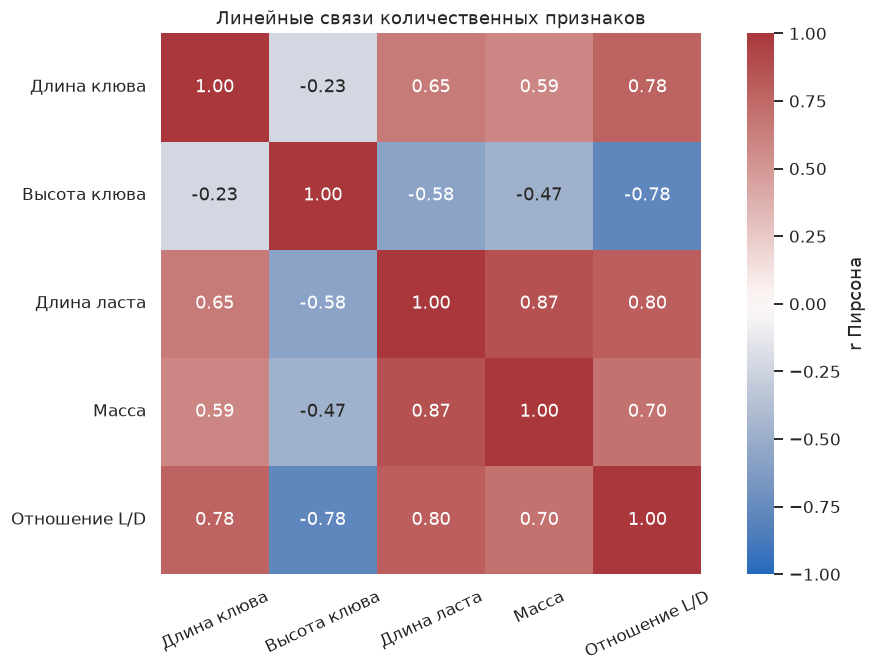

Масса и длина ласта имеют сильную положительную связь: **r = 0.873**. Сильнейшая пара по модулю: **flipper_length_mm - body_mass_g** (r = 0.873). Слабейшая: **bill_length_mm - bill_depth_mm** (r = -0.229). Слабая линейная связь не исключает нелинейной зависимости. Отношение L/D математически зависит от двух исходных размеров, поэтому его корреляции нельзя считать независимыми биологическими эффектами.

In [31]:
pearson_r = df_clean["body_mass_g"].corr(df_clean["flipper_length_mm"], method="pearson")
print(f"Корреляция Пирсона: масса и длина ласта, r = {pearson_r:.3f}")

corr_columns = NUMERIC + ["bill_ratio"]
corr = df_clean[corr_columns].corr(method="pearson")
display(corr.round(3))
pair_rows = []
for i, first in enumerate(corr_columns):
    for second in corr_columns[i + 1:]:
        pair_rows.append({"Первый признак": first, "Второй признак": second,
                          "r": corr.loc[first, second], "|r|": abs(corr.loc[first, second])})
correlation_pairs = pd.DataFrame(pair_rows).sort_values("|r|", ascending=False).reset_index(drop=True)
display(correlation_pairs)
strongest = correlation_pairs.iloc[0]
weakest = correlation_pairs.iloc[-1]

short_labels = {
    "bill_length_mm": "Длина клюва",
    "bill_depth_mm": "Высота клюва",
    "flipper_length_mm": "Длина ласта",
    "body_mass_g": "Масса",
    "bill_ratio": "Отношение L/D",
}
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
sns.heatmap(corr.rename(index=short_labels, columns=short_labels),
            annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag",
            square=True, cbar_kws={"label": "r Пирсона"}, ax=ax)
ax.set_title("Линейные связи количественных признаков")
ax.tick_params(axis="x", rotation=25)
ax.tick_params(axis="y", rotation=0)
plt.show()

display(Markdown(
    f"Масса и длина ласта имеют сильную положительную связь: **r = {pearson_r:.3f}**. "
    f"Сильнейшая пара по модулю: **{strongest['Первый признак']} - "
    f"{strongest['Второй признак']}** (r = {strongest['r']:.3f}). "
    f"Слабейшая: **{weakest['Первый признак']} - {weakest['Второй признак']}** "
    f"(r = {weakest['r']:.3f}). "
    "Слабая линейная связь не исключает нелинейной зависимости. "
    "Отношение L/D математически зависит от двух исходных размеров, "
    "поэтому его корреляции нельзя считать независимыми биологическими эффектами."
))

### Диаграмма рассеяния выбранной пары

Для самой сильной пары исходных измерений - длины ласта и массы тела - построим отдельный scatterplot непосредственно в разделе 8. Цвет показывает вид и помогает увидеть, какая часть общей связи объясняется различиями видов.

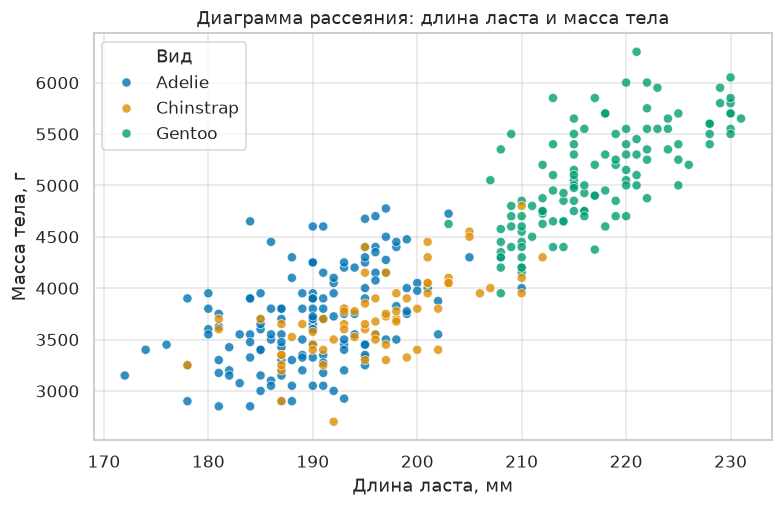

,r: масса и длина ласта внутри вида
Adelie,0.46
Chinstrap,0.64
Gentoo,0.71


Внутри каждого вида связь массы с длиной ласта также положительна, но слабее общей корреляции. Часть общей связи объясняется тем, что Gentoo одновременно тяжелее и имеет более длинные ласты. Корреляция сама по себе не доказывает причинность и не заменяет многомерную модель.

In [32]:
fig, ax = plt.subplots(figsize=(7, 4.5), layout="constrained")
sns.scatterplot(
    data=df_clean,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species",
    palette=PALETTE,
    alpha=0.8,
    ax=ax
)
ax.set_title("Диаграмма рассеяния: длина ласта и масса тела")
ax.set_xlabel("Длина ласта, мм")
ax.set_ylabel("Масса тела, г")
ax.legend(title="Вид")
plt.show()

within_species_r = pd.Series({
    species: part["body_mass_g"].corr(part["flipper_length_mm"])
    for species, part in df_clean.groupby("species", observed=True)
}, name="r: масса и длина ласта внутри вида")
display(within_species_r.to_frame())
display(Markdown(
    "Внутри каждого вида связь массы с длиной ласта также положительна, "
    "но слабее общей корреляции. Часть общей связи объясняется тем, что Gentoo "
    "одновременно тяжелее и имеет более длинные ласты. "
    "Корреляция сама по себе не доказывает причинность и не заменяет многомерную модель."
))

**Общий вывод корреляционного анализа.** Между длиной ласта и массой тела выявлена сильная положительная линейная связь (r = 0,873). На диаграмме Gentoo образуют группу с более длинными ластами и большей массой; внутри каждого вида связь положительна, но слабее общей (r от 0,46 до 0,71). Самая слабая по модулю связь - между длиной и высотой клюва (r = −0,229). Для прогноза массы используем несколько измерений, вид и пол; корреляции не доказывают причинного влияния.

## 9. Линейная регрессия

<a id="linear-regression"></a>

**Постановка задачи:** построить модель множественной линейной регрессии для прогнозирования массы тела пингвина (`body_mass_g`) по морфологическим измерениям (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`), а также видовой принадлежности (`species`) и полу (`sex`).

Признак `island` исключён, чтобы не дублировать информацию о виде и снизить риск мультиколлинеарности: видовой состав островов сильно различается. Признак `year` исключён как техническая характеристика сбора данных. Категориальные переменные кодируются с помощью **One-Hot Encoding** с удалением базовой категории (`drop='first'`), чтобы избежать ловушки фиктивных переменных. Базовые категории - Adelie и female.

Обучающая и тестовая выборки формируются в пропорции **80/20** с `random_state=SEED` (`SEED=42`), без стратификации. Обучение кодировщика и регрессии выполняется внутри Pipeline только по train. Производные признаки не включаем: они уже определяются исходными размерами.

**План оценки:** рассчитываем $R^2$, MSE, RMSE и MAE на отложенном тесте; дополнительно сравниваем с прогнозом средним значением train. Учебный ориентир качества - $R^2\geq0.80$, $MAE\leq300$ г и MAE ниже базовой модели. Пороги заданы для этого проекта; параметры по тесту не подбираем. Поскольку EDA описывает весь набор данных, для независимого подтверждения качества нужна новая выборка.

In [33]:
X = df_clean[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "species", "sex"]].copy()
y = df_clean["body_mass_g"].copy()

# 1. Разделение выборки на обучающую и тестовую (80/20).
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(df_clean)
print(f"Обучающая выборка: {len(X_train)}; тестовая: {len(X_test)}.")
display(pd.concat({
    "train": X_train.groupby(["species", "sex"], observed=True).size(),
    "test": X_test.groupby(["species", "sex"], observed=True).size(),
}, axis=1).fillna(0).astype(int))

# Подготовка пайплайна с кодированием категориальных признаков.
cat_cols = ["species", "sex"]
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols),
    ]
)
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])

# 2. Обучение модели.
model_pipeline.fit(X_train, y_train)

# Извлечение названий признаков и коэффициентов.
feature_names = num_cols + list(
    model_pipeline.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .get_feature_names_out(cat_cols)
)
coefficients = model_pipeline.named_steps["regressor"].coef_
intercept = model_pipeline.named_steps["regressor"].intercept_

coef_df = pd.DataFrame({
    "Признак": ["Свободный член (Intercept)"] + feature_names,
    "Коэффициент": [intercept] + list(coefficients),
})
display(coef_df)

# 3. Оценка качества на тестовой выборке.
y_pred = model_pipeline.predict(X_test)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

metrics_df = pd.DataFrame({
    "Метрика": ["R²", "MSE", "RMSE", "MAE"],
    "Значение на тестовой выборке": [
        f"{r2:.4f}", f"{mse:,.2f} г²", f"{rmse:.2f} г", f"{mae:.2f} г",
    ],
})
display(metrics_df)

# Базовая модель для содержательного сравнения качества.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

Обучающая выборка: 266; тестовая: 67.


train  test
species   sex                
Adelie    female     55    18
          male       60    13
Chinstrap female     26     8
          male       24    10
Gentoo    female     48    10
          male       53     8

,Признак,Коэффициент
0,Свободный член (Intercept),"-1,328.02"
1,bill_length_mm,21.29
2,bill_depth_mm,69.30
3,flipper_length_mm,14.35
4,species_Chinstrap,-246.74
5,species_Gentoo,"1,035.59"
6,sex_male,391.46


,Метрика,Значение на тестовой выборке
0,R²,0.8728
1,MSE,"76,042.78 г²"
2,RMSE,275.76 г
3,MAE,204.64 г


,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[4232.61]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](5,)","['bill_length_mm','bill_depth_mm','flipper_length_mm','species','sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,5
n_outputs_ n_outputs_: intNumber of outputs.,int,1


### Интерпретация модели и уравнения регрессии

**Общая форма уравнения полученной модели:**

$$
\widehat{m}=\beta_0+\beta_1L+\beta_2D+\beta_3F+
\beta_4I_{\mathrm{Chinstrap}}+\beta_5I_{\mathrm{Gentoo}}+\beta_6I_{\mathrm{male}}.
$$

Здесь $m$ - `body_mass_g` в граммах; $L$ - длина клюва, $D$ - высота клюва, $F$ - длина ласта (все в мм). Индикаторы вида и пола равны 1 при принадлежности к соответствующей категории и 0 иначе. Базовая группа - **самки Adelie**.

**Численное уравнение обученной модели** (коэффициенты округлены до сотых):

$$
\begin{aligned}
\widehat{m} ={}& -1328.02 + 21.29L + 69.30D + 14.35F\\
&-246.74I_{\mathrm{Chinstrap}}+1035.59I_{\mathrm{Gentoo}}+391.46I_{\mathrm{male}}.
\end{aligned}
$$

При одинаковых остальных признаках увеличение длины клюва на 1 мм связано с **+21,29 г**, высоты клюва - с **+69,30 г**, длины ласта - с **+14,35 г** прогнозируемой массы. Для Chinstrap прогноз ниже Adelie на **246,74 г**, для Gentoo - выше на **1035,59 г**. Условная разница самцов и самок - **+391,46 г**. Это ассоциации в модели, а не доказанные причинные эффекты.

**Смысл коэффициентов:**

- Коэффициент размера показывает изменение прогнозной массы в граммах при увеличении этого размера на 1 мм **при одинаковых остальных признаках**. Положительные коэффициенты длины клюва и ласта согласуются с увеличением массы у более крупных птиц.
- Коэффициент `sex_male` описывает условную разницу самцов и самок. Его положительное значение согласуется с половым диморфизмом, но само по себе не доказывает статистической значимости: стандартные ошибки и p-value коэффициентов здесь не рассчитывались.
- Коэффициент `species_Gentoo` показывает отличие от Adelie при одинаковых измерениях и поле. Положительное значение согласуется с большей массой Gentoo в EDA.
- Свободный член - прогноз при нулевых размерах в базовой группе; самостоятельного биологического смысла он не имеет.

Ниже приведены **численные коэффициенты, фактическое уравнение** и их интерпретация. Связи описывают ассоциации, а не причинные эффекты; парные корреляции и условные коэффициенты могут различаться.

In [34]:
regression = model_pipeline.named_steps["regressor"]
coefficients = pd.Series(regression.coef_, index=feature_names, name="Коэффициент")
intercept = float(regression.intercept_)
explanations = {
    "bill_length_mm": "Изменение прогноза, г, при +1 мм длины клюва",
    "bill_depth_mm": "Изменение прогноза, г, при +1 мм высоты клюва",
    "flipper_length_mm": "Изменение прогноза, г, при +1 мм длины ласта",
    "species_Chinstrap": "Разница Chinstrap относительно Adelie, г",
    "species_Gentoo": "Разница Gentoo относительно Adelie, г",
    "sex_male": "Разница самцов относительно самок, г",
}
coefficient_table = coefficients.to_frame()
coefficient_table["Интерпретация при прочих равных"] = [
    explanations[name] for name in feature_names
]
display(coefficient_table)
print(f"Свободный член: {intercept:.2f} г")

symbols = ["L", "D", "F", r"I_{\mathrm{Chinstrap}}", r"I_{\mathrm{Gentoo}}", r"I_{\mathrm{male}}"]
equation = rf"\widehat{{m}} = {intercept:.2f}"
for coefficient, symbol in zip(regression.coef_, symbols):
    sign = "+" if coefficient >= 0 else "-"
    equation += rf" {sign} {abs(coefficient):.2f}\,{symbol}"
display(Markdown("**Полученное уравнение (масса в граммах):**"))
display(Markdown(chr(36) * 2 + equation + chr(36) * 2))
display(Markdown(
    f"Например, дополнительный 1 мм длины ласта связан с изменением прогноза на "
    f"**{coefficients['flipper_length_mm']:.1f} г** при одинаковых остальных признаках. "
    f"Условная разница самцов и самок - **{coefficients['sex_male']:.1f} г**. "
    "Она отличается от разницы средних в разделе 6: модель дополнительно учитывает размеры и вид. "
    "Свободный член соответствует нулевым размерам и не имеет самостоятельного биологического смысла. "
    "Коэффициенты описывают ассоциации; сравнивать их модули как «важность» нельзя без учёта масштаба и зависимости предикторов."
))

,Коэффициент,Интерпретация при прочих равных
bill_length_mm,21.29,"Изменение прогноза, г, при +1 мм длины клюва"
bill_depth_mm,69.30,"Изменение прогноза, г, при +1 мм высоты клюва"
flipper_length_mm,14.35,"Изменение прогноза, г, при +1 мм длины ласта"
species_Chinstrap,-246.74,"Разница Chinstrap относительно Adelie, г"
species_Gentoo,"1,035.59","Разница Gentoo относительно Adelie, г"
sex_male,391.46,"Разница самцов относительно самок, г"


Свободный член: -1328.02 г


**Полученное уравнение (масса в граммах):**

$$\widehat{m} = -1328.02 + 21.29\,L + 69.30\,D + 14.35\,F - 246.74\,I_{\mathrm{Chinstrap}} + 1035.59\,I_{\mathrm{Gentoo}} + 391.46\,I_{\mathrm{male}}$$

Например, дополнительный 1 мм длины ласта связан с изменением прогноза на **14.4 г** при одинаковых остальных признаках. Условная разница самцов и самок - **391.5 г**. Она отличается от разницы средних в разделе 6: модель дополнительно учитывает размеры и вид. Свободный член соответствует нулевым размерам и не имеет самостоятельного биологического смысла. Коэффициенты описывают ассоциации; сравнивать их модули как «важность» нельзя без учёта масштаба и зависимости предикторов.

### 9.3. Качество на тестовой выборке

$$MSE=\frac1n\sum(y_i-\widehat y_i)^2,\qquad
MAE=\frac1n\sum|y_i-\widehat y_i|,\qquad
R^2=1-\frac{\sum(y_i-\widehat y_i)^2}{\sum(y_i-\bar y_{\mathrm{test}})^2}.$$

MAE измеряется в граммах и показывает среднюю абсолютную ошибку, MSE - в г² и сильнее штрафует большие ошибки. Дополнительно считаем $RMSE=\sqrt{MSE}$ в граммах. $R^2$ оценивает долю вариации тестовой массы, объяснённую моделью относительно среднего теста; это не «процент точных прогнозов».

In [35]:
y_pred = model_pipeline.predict(X_test)
baseline_pred = baseline.predict(X_test)

def regression_metrics(y_true, prediction):
    mse = mean_squared_error(y_true, prediction)
    return {
        "R²": r2_score(y_true, prediction),
        "MSE, г²": mse,
        "MAE, г": mean_absolute_error(y_true, prediction),
        "RMSE, г": np.sqrt(mse),
    }

metrics = pd.DataFrame({
    "Среднее train": regression_metrics(y_test, baseline_pred),
    "Линейная регрессия": regression_metrics(y_test, y_pred),
}).T
display(metrics)
test_results = X_test.copy()
test_results["Факт, г"] = y_test
test_results["Прогноз, г"] = y_pred
test_results["Остаток, г"] = y_test - y_pred
test_results["Абсолютная ошибка, г"] = np.abs(y_test - y_pred)
display(test_results.head(10))
test_mae_by_species = test_results.groupby("species", observed=True).agg(
    n=("Абсолютная ошибка, г", "count"),
    MAE_g=("Абсолютная ошибка, г", "mean"),
)
display(test_mae_by_species)

model_metrics = metrics.loc["Линейная регрессия"]
mae_reduction = 1 - model_metrics["MAE, г"] / metrics.loc["Среднее train", "MAE, г"]
quality_ok = (
    model_metrics["R²"] >= 0.80 and
    model_metrics["MAE, г"] <= 300 and
    model_metrics["MAE, г"] < metrics.loc["Среднее train", "MAE, г"]
)
quality_text = "выполнен" if quality_ok else "не выполнен"
display(Markdown(
    f"На тесте **R² = {model_metrics['R²']:.3f}**, "
    f"**MSE = {model_metrics['MSE, г²']:.0f} г²**, "
    f"**MAE = {model_metrics['MAE, г']:.0f} г**, "
    f"RMSE = {model_metrics['RMSE, г']:.0f} г. "
    f"MAE ниже базового прогноза на **{mae_reduction:.1%}**. "
    f"Заданный учебный ориентир качества **{quality_text}**. "
    "Модель пригодна для приблизительной оценки массы похожих птиц, "
    "но не заменяет взвешивание. Ошибки отдельных прогнозов могут быть гораздо больше MAE; "
    "одного небольшого тестового разбиения недостаточно для оценки переноса на новые колонии."
))

,R²,"MSE, г²","MAE, г","RMSE, г"
Среднее train,-0.03,"614,002.80",659.39,783.58
Линейная регрессия,0.87,"76,042.78",204.64,275.76


,bill_length_mm,bill_depth_mm,flipper_length_mm,species,sex,"Факт, г","Прогноз, г","Остаток, г","Абсолютная ошибка, г"
30,39.50,16.70,178.00,Adelie,female,"3,250.00","3,224.88",25.12,25.12
320,50.90,17.90,196.00,Chinstrap,female,"3,675.00","3,562.31",112.69,112.69
79,42.10,19.10,195.00,Adelie,male,"4,000.00","4,082.01",-82.01,82.01
202,46.60,14.20,210.00,Gentoo,female,"4,850.00","4,697.62",152.38,152.38
63,41.10,18.20,192.00,Adelie,male,"4,050.00","3,955.29",94.71,94.71
307,54.20,20.80,201.00,Chinstrap,male,"4,300.00","4,296.75",3.25,3.25
292,50.30,20.00,197.00,Chinstrap,male,"3,300.00","4,100.89",-800.89,800.89
187,48.40,16.30,220.00,Gentoo,male,"5,400.00","5,416.45",-16.45,16.45
219,49.50,16.20,229.00,Gentoo,male,"5,800.00","5,562.11",237.89,237.89
204,45.10,14.40,210.00,Gentoo,female,"4,400.00","4,679.55",-279.55,279.55


,n,MAE_g
species,,
Adelie,31,202.43
Chinstrap,18,197.48
Gentoo,18,215.58


На тесте **R² = 0.873**, **MSE = 76043 г²**, **MAE = 205 г**, RMSE = 276 г. MAE ниже базового прогноза на **69.0%**. Заданный учебный ориентир качества **выполнен**. Модель пригодна для приблизительной оценки массы похожих птиц, но не заменяет взвешивание. Ошибки отдельных прогнозов могут быть гораздо больше MAE; одного небольшого тестового разбиения недостаточно для оценки переноса на новые колонии.

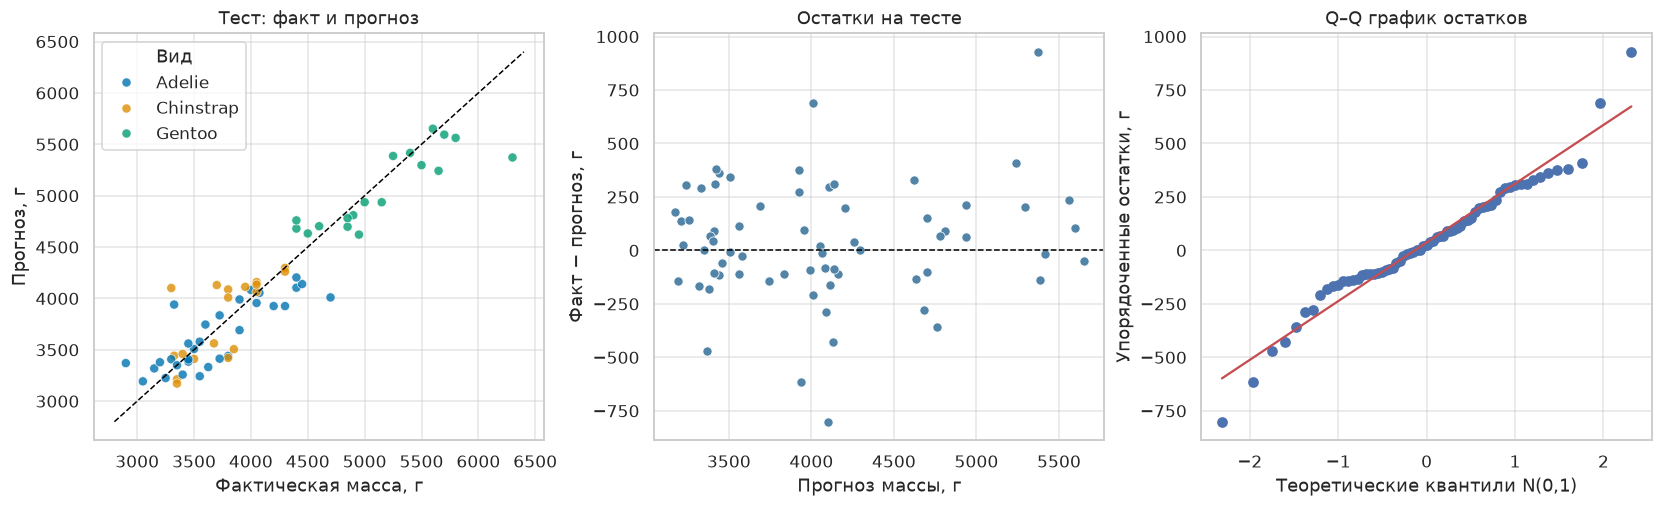

Средний остаток на тесте: 37.3 г.
Максимальная абсолютная ошибка: 928.4 г.


In [36]:
residuals = y_test.to_numpy() - y_pred
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
sns.scatterplot(x=y_test, y=y_pred, hue=X_test["species"],
                palette=PALETTE, alpha=0.8, ax=axes[0])
limits = [min(y_test.min(), y_pred.min()) - 100, max(y_test.max(), y_pred.max()) + 100]
axes[0].plot(limits, limits, "--", color="black", linewidth=1)
axes[0].set(title="Тест: факт и прогноз", xlabel="Фактическая масса, г", ylabel="Прогноз, г")
axes[0].legend(title="Вид")
sns.scatterplot(x=y_pred, y=residuals, ax=axes[1], color="#5284a8")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Остатки на тесте", xlabel="Прогноз массы, г", ylabel="Факт − прогноз, г")
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set(title="Q–Q график остатков", xlabel="Теоретические квантили N(0,1)",
            ylabel="Упорядоченные остатки, г")
plt.show()
print(f"Средний остаток на тесте: {residuals.mean():.1f} г.")
print(f"Максимальная абсолютная ошибка: {np.abs(residuals).max():.1f} г.")

### Интерпретация качества модели и диагностика

**Качество на тестовой выборке.** Коэффициент детерминации $R^2=0.8728\approx0.87$ означает, что модель объясняет около **87% вариации массы** на отложенных наблюдениях относительно прогноза средним значением теста. Это не доля «точных» предсказаний.

Средняя абсолютная ошибка **MAE = 204,64 г** меньше 300 г при размахе массы 3600 г; **MSE = 76 042,78 г²**, **RMSE = 275,76 г**. MAE ниже базовой модели примерно на **69%**. Учебный ориентир качества выполнен: модель даёт полезную приближённую оценку массы птиц из похожей популяции.

**Диагностика.** Точки «факт - прогноз» в основном расположены около диагонали. Средний остаток «факт минус прогноз» равен **+37 г**: на тесте модель в среднем немного занижает массу. Максимальная абсолютная ошибка - **928 г**, то есть ошибка отдельного прогноза может быть существенно выше MAE. В Q–Q графике следует обращать внимание на хвосты распределения; нормальность и постоянство дисперсии по одному графику не доказаны. MAE по видам близки (197–216 г), но тестовые группы невелики: Adelie - 31 птица, Chinstrap и Gentoo - по 18.

**Возможность применения.** Для предварительной оценки модель перспективна, однако высокое качество на одном разбиении не подтверждает готовность к практическому применению в новых колониях. Нужны внешняя проверка, интервалы прогноза и оценка устойчивости коэффициентов. Коррелирующие размеры и предположение одинаковых наклонов для всех видов ограничивают интерпретацию. Линейные промеры сами по себе не делают процедуру бесконтактной. Параметры модели по результатам теста не перенастраиваются.

## 10. Итоговые выводы

<a id="final-conclusions"></a>

1. **Морфологическая дифференциация видов.** Разведочный анализ показал разделение видов по массе и размерам. Gentoo - самый крупный вид: средняя масса около **5092 г**. Adelie и Chinstrap близки по массе (**3706 и 3733 г**), но различаются пропорциями клюва. Все 67 птиц массой от 5000 г относятся к Gentoo.
2. **Половой диморфизм.** Во всех трёх видах средняя масса самцов выше средней массы самок. Для Adelie двусторонний t-критерий Уэлча подтвердил статистически значимое различие средних: **p ≈ 6,4 × 10⁻²⁶ < 0,001**, разница около **675 г** в пользу самцов; 95% доверительный интервал - **[573; 776] г**. Это сравнение средних при допущении независимости наблюдений, а не доказательство причинного влияния.
3. **Линейные взаимосвязи.** Среди исходных измерений наиболее сильная линейная связь с массой - у длины ласта (**r = 0,873**). Диаграмма рассеяния показывает межвидовые смещения; внутри видов корреляции ниже (0,46–0,71). Поэтому для прогноза учитываем не только длину ласта, но и остальные размеры, вид и пол. Самая слабая по модулю связь - между длиной и высотой клюва (r = −0,229).
4. **Результаты моделирования.** Множественная линейная регрессия по морфологическим измерениям, виду и полу на отложенной тестовой выборке дала **R² = 0,8728 ≈ 0,87**, **MSE = 76 042,78 г²**, **MAE = 204,64 г < 300 г**, **RMSE = 275,76 г**. MAE примерно на 69% ниже базового прогноза средним train. Модель подходит для приближённой оценки массы похожих птиц по линейным промерам. При одинаковых остальных признаках дополнительный миллиметр ласта связан с +14,4 г прогнозируемой массы, а принадлежность к самцам - примерно с +391 г относительно самок. Статистическая значимость отдельных коэффициентов здесь не проверялась.

**Подготовка и ограничения.** Из 344 исходных записей после удаления 11 неполных осталось 333; дубликатов нет. Четыре крайних значения внутри видов сохранены как возможные биологические наблюдения. Средняя масса - 4207 г, медиана - 4050 г, стандартное отклонение - 805 г; центральные 50% лежат от 3550 до 4775 г. Пропуски, возможная зависимость птиц одной колонии и небольшая тестовая выборка ограничивают переносимость результатов. Максимальная ошибка прогноза составила 928 г. Для практического использования нужны независимая проверка на новых данных и интервалы прогноза; модель не заменяет взвешивание.

### Сохранение результатов

Обработанная таблица сохраняется отдельно от исходной, а метрики, коэффициенты и тестовые прогнозы - в папку `results`. Численные выводы соответствуют приложенному CSV и разбиению 80/20 с `SEED=42`.